In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "../datafolder/"

sleep = pd.read_csv(DATA_DIR + "minuteSleep_merged.csv")
weight = pd.read_csv(DATA_DIR + "weightLogInfo_merged.csv")
steps_wide = pd.read_csv(DATA_DIR + "minuteStepsWide_merged.csv")

In [2]:
def first_look(df, name):
    """Print a quick quality summary of a dataframe."""
    print(f"\n===== {name} =====")
    print("Shape (rows, columns):", df.shape)
    print("Distinct users:", df["Id"].nunique())
    print("Duplicate rows:", df.duplicated().sum())
    missing = df.isna().sum()
    print("Missing values:\n", missing[missing > 0] if missing.any() else "None")
    print("\nColumn types:\n", df.dtypes.head(8))
    display(df.head(3))

for df, name in [(sleep, "minuteSleep"), (weight, "weightLogInfo"), (steps_wide, "minuteStepsWide")]:
    first_look(df, name)


===== minuteSleep =====
Shape (rows, columns): (188521, 4)
Distinct users: 24
Duplicate rows: 543
Missing values:
 None

Column types:
 Id       int64
date       str
value    int64
logId    int64
dtype: object


,Id,date,value,logId
0,1503960366,4/12/2016 2:47:30 AM,3,11380564589
1,1503960366,4/12/2016 2:48:30 AM,2,11380564589
2,1503960366,4/12/2016 2:49:30 AM,1,11380564589



===== weightLogInfo =====
Shape (rows, columns): (67, 8)
Distinct users: 8
Duplicate rows: 0
Missing values:
 Fat    65
dtype: int64

Column types:
 Id                  int64
Date                  str
WeightKg          float64
WeightPounds      float64
Fat               float64
BMI               float64
IsManualReport       bool
LogId               int64
dtype: object


,Id,Date,WeightKg,WeightPounds,Fat,BMI,IsManualReport,LogId
0,1503960366,5/2/2016 11:59:59 PM,52.599998,115.963147,22.0,22.650000,True,1462233599000
1,1503960366,5/3/2016 11:59:59 PM,52.599998,115.963147,NaN,22.650000,True,1462319999000
2,1927972279,4/13/2016 1:08:52 AM,133.500000,294.317120,NaN,47.540001,False,1460509732000



===== minuteStepsWide =====
Shape (rows, columns): (21645, 62)
Distinct users: 33
Duplicate rows: 0
Missing values:
 None

Column types:
 Id              int64
ActivityHour      str
Steps00         int64
Steps01         int64
Steps02         int64
Steps03         int64
Steps04         int64
Steps05         int64
dtype: object


,Id,ActivityHour,Steps00,Steps01,Steps02,Steps03,Steps04,Steps05,Steps06,Steps07,...,Steps50,Steps51,Steps52,Steps53,Steps54,Steps55,Steps56,Steps57,Steps58,Steps59
0,1503960366,4/13/2016 12:00:00 AM,4,16,0,0,0,9,0,17,...,0,9,8,0,20,1,0,0,0,0
1,1503960366,4/13/2016 1:00:00 AM,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1503960366,4/13/2016 2:00:00 AM,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Remove exact duplicate rows
sleep = sleep.drop_duplicates()

# Convert the text dates into real datetimes (giving the format makes it much faster)
sleep["date"] = pd.to_datetime(sleep["date"], format="%m/%d/%Y %I:%M:%S %p")

print("Date range:", sleep["date"].min(), "to", sleep["date"].max())
print("\nHow often each 'value' code appears:")
print(sleep["value"].value_counts().sort_index())

Date range: 2016-04-11 20:48:00 to 2016-05-12 09:56:00

How often each 'value' code appears:
value
1    171960
2     14002
3      2016
Name: count, dtype: int64


In [4]:
# Each logId is one sleep session. Group the minutes into sessions.
sessions = (
    sleep.groupby(["Id", "logId"])
    .agg(
        start=("date", "min"),       # first minute = fell asleep / got into bed
        end=("date", "max"),         # last minute = woke up
        minutes=("value", "size"),   # total minutes recorded
        asleep=("value", lambda v: (v == 1).sum()),
        restless=("value", lambda v: (v == 2).sum()),
        awake=("value", lambda v: (v == 3).sum()),
    )
    .reset_index()
)
sessions["hours"] = sessions["minutes"] / 60

display(sessions.head())
print(sessions["hours"].describe().round(2))
print("\nSessions per user:")
print(sessions.groupby("Id").size().sort_values(ascending=False))
print("\nSessions shorter than 2 hours (possible naps):", (sessions["hours"] < 2).sum())

,Id,logId,start,end,minutes,asleep,restless,awake,hours
0,1503960366,11380564589,2016-04-12 02:47:30,2016-04-12 08:32:30,346,327,13,6,5.766667
1,1503960366,11388770715,2016-04-13 03:08:30,2016-04-13 08:20:30,313,290,11,12,5.216667
2,1503960366,11388770716,2016-04-13 20:10:00,2016-04-13 21:43:00,94,94,0,0,1.566667
3,1503960366,11402722600,2016-04-15 02:59:00,2016-04-15 10:20:00,442,412,22,8,7.366667
4,1503960366,11421831252,2016-04-16 02:11:00,2016-04-16 06:59:00,289,270,16,3,4.816667


count    459.00
mean       6.83
std        2.64
min        1.00
25%        5.77
50%        7.43
75%        8.43
max       16.02
Name: hours, dtype: float64

Sessions per user:
Id
4445114986    39
5553957443    38
8378563200    35
6962181067    34
3977333714    32
4388161847    30
4702921684    29
2026352035    28
5577150313    27
1503960366    27
4319703577    27
7086361926    24
6117666160    22
2347167796    15
8792009665    15
1927972279     8
4020332650     8
4558609924     5
1644430081     4
1844505072     3
8053475328     3
6775888955     3
7007744171     2
2320127002     1
dtype: int64

Sessions shorter than 2 hours (possible naps): 41


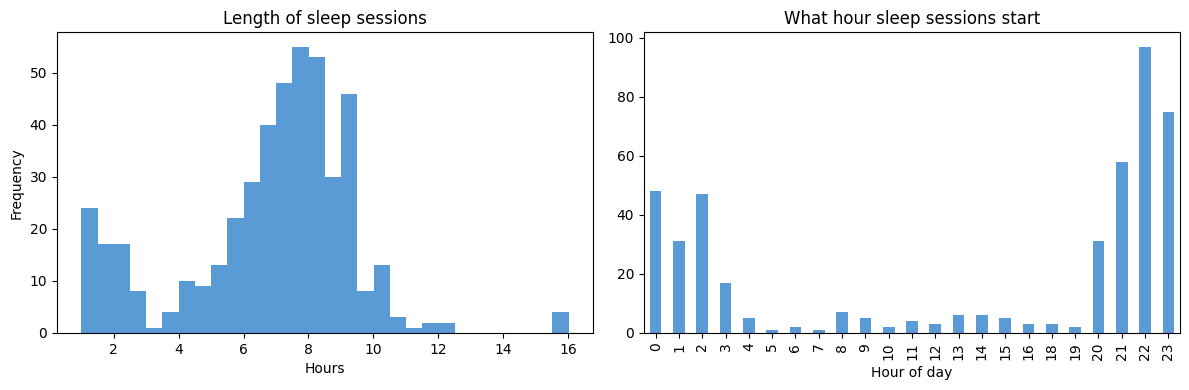

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

sessions["hours"].plot.hist(bins=30, ax=ax1, color="#5b9bd5")
ax1.set_title("Length of sleep sessions")
ax1.set_xlabel("Hours")

sessions["start"].dt.hour.value_counts().sort_index().plot.bar(ax=ax2, color="#5b9bd5")
ax2.set_title("What hour sleep sessions start")
ax2.set_xlabel("Hour of day")

plt.tight_layout()
plt.show()

### minuteSleep: initial findings

**Coverage**
- 24 of 33 users have minute-level sleep data, so 9 users have no sleep data at all.
- Logging is very uneven: sessions per user range from 1 to 39. 13 users have 20+ sessions, while 7 users have 5 or fewer.

**Data quality**
- 543 exact duplicate rows were found and removed (188,521 → 187,978 rows).
- The date range starts on 11 April at 20:48, the evening before the activity data begins (12 April). This is because the first night's sleep started the night before.
- The `value` column isn't documented in the source. It's commonly read as 1 = asleep, 2 = restless, 3 = awake. On that reading, 91.5% of minutes are asleep, 7.4% restless and 1.1% awake.

**Sleep sessions** (one per `logId`)
- 459 sessions in total. Median length 7.4 hours, mean 6.8 hours.
- 41 sessions are under 2 hours, likely naps rather than main sleep.
- 6 sessions are over 12 hours, which may be genuine lie-ins or the tracker left on.

**Timing**
- Main sleep (2+ hours) most often starts between 10pm and midnight, with 10pm the most common hour.
- Some main sleep sessions start between midnight and 3am, so a sleep that starts after midnight belongs to the previous night.

**Implications for the dashboard**
- **Missing sleep data must be handled explicitly.** 9 of 33 users have no sleep data, and several have only a handful of nights. The dashboard should show a clear "no sleep data recorded" message rather than a blank or zero, and group sleep comparisons should only include users with enough nights (e.g. 10+) to be meaningful.
- **Naps should be separated from main sleep.** Counting the 41 short sessions as nights would drag down average sleep for those users. Treating sessions under 2 hours as naps, and reporting them separately, gives a fairer picture of nightly sleep.
- **Sleep needs to be assigned to the right night.** Sessions starting after midnight belong to the previous evening. Assigning each session to a "sleep night" (e.g. any start before midday counts as the previous night) is essential if the dashboard links sleep to the next day's activity. Otherwise the wrong days get matched.

In [7]:
weight["Date"] = pd.to_datetime(weight["Date"], format="%m/%d/%Y %I:%M:%S %p")

print("Entries per user:")
print(weight.groupby("Id").size().sort_values(ascending=False))

print("\nSummary:")
print(weight[["WeightKg", "BMI", "Fat"]].describe().round(1))

print("\nManual vs automatic entries:")
print(weight["IsManualReport"].value_counts())

Entries per user:
Id
6962181067    30
8877689391    24
4558609924     5
1503960366     2
2873212765     2
4319703577     2
1927972279     1
5577150313     1
dtype: int64

Summary:
       WeightKg   BMI   Fat
count      67.0  67.0   2.0
mean       72.0  25.2  23.5
std        13.9   3.1   2.1
min        52.6  21.5  22.0
25%        61.4  24.0  22.8
50%        62.5  24.4  23.5
75%        85.0  25.6  24.2
max       133.5  47.5  25.0

Manual vs automatic entries:
IsManualReport
True     41
False    26
Name: count, dtype: int64


In [8]:
# Is WeightPounds just WeightKg converted? (1 kg = 2.20462 lb)
diff = (weight["WeightKg"] * 2.20462 - weight["WeightPounds"]).abs().max()
print("Biggest difference between kg-converted and pounds:", diff)

# LogId looks like a big number. Try reading it as a timestamp in milliseconds.
weight["LogId_as_date"] = pd.to_datetime(weight["LogId"], unit="ms")
display(weight[["Date", "LogId_as_date"]].head())

Biggest difference between kg-converted and pounds: 0.0003500169750623172


,Date,LogId_as_date
0,2016-05-02 23:59:59,2016-05-02 23:59:59
1,2016-05-03 23:59:59,2016-05-03 23:59:59
2,2016-04-13 01:08:52,2016-04-13 01:08:52
3,2016-04-21 23:59:59,2016-04-21 23:59:59
4,2016-05-12 23:59:59,2016-05-12 23:59:59


In [9]:
# BMI = weight / height², so height = √(weight / BMI)
weight["height_m"] = np.sqrt(weight["WeightKg"] / weight["BMI"])
print("Derived height per user (mean, std):")
print(weight.groupby("Id")["height_m"].agg(["mean", "std"]).round(3))

# Weight change from first to last entry
change = weight.sort_values("Date").groupby("Id")["WeightKg"].agg(first="first", last="last", entries="size")
change["change_kg"] = change["last"] - change["first"]
display(change.round(1))

Derived height per user (mean, std):
             mean    std
Id                      
1503960366  1.524  0.000
1927972279  1.676    NaN
2873212765  1.626  0.000
4319703577  1.625  0.001
4558609924  1.600  0.000
5577150313  1.800    NaN
6962181067  1.601  0.000
8877689391  1.828  0.000


,first,last,entries,change_kg
Id,,,,
1503960366,52.6,52.6,2,0.0
1927972279,133.5,133.5,1,0.0
2873212765,56.7,57.3,2,0.6
4319703577,72.4,72.3,2,-0.1
4558609924,69.7,69.1,5,-0.6
5577150313,90.7,90.7,1,0.0
6962181067,62.5,61.9,30,-0.6
8877689391,85.8,84.0,24,-1.8


### weightLogInfo: initial findings

**Coverage**
- Only 8 of 33 users logged weight, with 67 entries in total.
- Logging is extremely uneven: 2 users account for 54 of the 67 entries (30 and 24). The other 6 users logged between 1 and 5 times each.

**Data quality**
- `Fat` is almost entirely empty: 65 of 67 values are missing, leaving only 2 readings.
- `WeightPounds` is just `WeightKg` converted (max difference 0.0004 lb), so it's redundant.
- `LogId` is a Unix timestamp in milliseconds and matches the `Date` column exactly, so it adds no new information.
- 61% of entries (41) are manual and 39% (26) automatic. Almost all automatic entries come from one user, likely using a smart scale.
- Many manual entries are timestamped 11:59:59 PM, which looks like a default "end of day" time rather than when the user actually weighed themselves.

**Values**
- Weight ranges from 52.6 to 133.5 kg, and BMI from 21.5 to 47.5. The highest values come from a single entry from one user.
- Height derived from BMI (√(weight ÷ BMI)) is constant for each user, ranging from 1.52 to 1.83 m. This suggests BMI is calculated from a fixed height in the user's profile.
- Weight barely changes over the month: between −1.8 kg and +0.6 kg per user.

**Implications for the dashboard**
- **Weight isn't suitable for group comparison.** With only 8 users, and most of the data from 2 people, any group average or ranking would be misleading. It works better as an optional panel in an individual user's view, shown only where data exists.
- **Drop the redundant and empty columns.** `WeightPounds`, `LogId` and `Fat` can be removed in cleaning, which simplifies the database. Pounds can be calculated from kg if users want them.
- **Weight and BMI are sensitive personal data.** Even in a friend group, people may not want their weight visible to others. The dashboard should make this panel private to the individual, or opt-in. This is also a good non-functional (privacy) requirement.

In [10]:
steps_wide["ActivityHour"] = pd.to_datetime(steps_wide["ActivityHour"], format="%m/%d/%Y %I:%M:%S %p")
print("Date range:", steps_wide["ActivityHour"].min(), "to", steps_wide["ActivityHour"].max())
print("Step columns:", [c for c in steps_wide.columns if c.startswith("Steps")][:5], "... to Steps59")

Date range: 2016-04-13 00:00:00 to 2016-05-13 08:00:00
Step columns: ['Steps00', 'Steps01', 'Steps02', 'Steps03', 'Steps04'] ... to Steps59


In [11]:
# melt turns the 60 minute columns into rows: one row per user per minute
steps_long = steps_wide.melt(
    id_vars=["Id", "ActivityHour"],
    var_name="minute_col",
    value_name="Steps",
)


steps_long["minute"] = steps_long["minute_col"].str.replace("Steps", "").astype(int)
steps_long["ActivityMinute"] = steps_long["ActivityHour"] + pd.to_timedelta(steps_long["minute"], unit="min")

steps_long = (
    steps_long[["Id", "ActivityMinute", "Steps"]]
    .sort_values(["Id", "ActivityMinute"])
    .reset_index(drop=True)
)

print("Wide shape:", steps_wide.shape, "→ long shape:", steps_long.shape)
display(steps_long.head())
print("Negative steps:", (steps_long["Steps"] < 0).sum(), "| Max steps in one minute:", steps_long["Steps"].max())

Wide shape: (21645, 62) → long shape: (1298700, 3)


,Id,ActivityMinute,Steps
0,1503960366,2016-04-13 00:00:00,4
1,1503960366,2016-04-13 00:01:00,16
2,1503960366,2016-04-13 00:02:00,0
3,1503960366,2016-04-13 00:03:00,0
4,1503960366,2016-04-13 00:04:00,0


Negative steps: 0 | Max steps in one minute: 220


In [13]:
narrow = pd.read_csv(DATA_DIR + "minuteStepsNarrow_merged.csv")
narrow["ActivityMinute"] = pd.to_datetime(narrow["ActivityMinute"], format="%m/%d/%Y %I:%M:%S %p")

print("Narrow:", narrow.shape, narrow["ActivityMinute"].min(), "to", narrow["ActivityMinute"].max())
print("Wide (reshaped):", steps_long.shape, steps_long["ActivityMinute"].min(), "to", steps_long["ActivityMinute"].max())

# Line the two up on user + minute and check whether the step counts agree
both = steps_long.merge(narrow, on=["Id", "ActivityMinute"], how="inner", suffixes=("_wide", "_narrow"))
print("\nMinutes in both files:", len(both))
print("% where step counts match:", round((both["Steps_wide"] == both["Steps_narrow"]).mean() * 100, 2))

Narrow: (1325580, 3) 2016-04-12 00:00:00 to 2016-05-12 15:59:00
Wide (reshaped): (1298700, 3) 2016-04-13 00:00:00 to 2016-05-13 08:59:00

Minutes in both files: 1278060
% where step counts match: 100.0


### minuteStepsWide: initial findings

**Structure**
- 21,645 rows × 62 columns, covering all 33 users. No duplicates or missing values.
- Each row is **one user for one hour**, and the 60 columns `Steps00` to `Steps59` hold the steps for each minute of that hour. This is "wide" format.
- Wide format is awkward for analysis: you can't easily filter by minute, plot over time, or join to other files. Reshaping it with `pd.melt()` gives "long" (narrow) format, one row per user per minute: 1,298,700 rows.
- Values look valid: no negative step counts, and a maximum of 220 steps in a single minute.

**Comparison with minuteStepsNarrow**
- Where both files cover the same user and minute (1,278,060 minutes), the step counts match **100%**. It's the same data in a different shape.
- However, **neither file is complete**:
  - The narrow file has the whole of **12 April** (47,520 minutes, all 33 users), which is missing from the wide file. The wide file starts on 13 April.
  - The wide file has **20,640 extra minutes** from 11 to 13 May, for 19 users, that aren't in the narrow file. These contain real activity (118,475 steps), not empty padding.
- The wide file runs to 13 May at 08:59, past the 12 May end date of the daily files.

**Implications for the dashboard**
- **Use the narrow file as the main source for minute-level steps.** It's already tidy, it starts on 12 April like the daily and hourly files, so dates line up across the dashboard, and the team only needs one format in the database.
- **The wide file shouldn't be stored as well.** Storing both would duplicate over a million rows. If the team wants the extra May minutes, they could be reshaped and appended to the narrow data once, during cleaning.
- **The files were exported at different times**, so the date ranges don't line up. The team should agree one fixed date range for the whole dashboard (e.g. 12 April to 11 May, the last full day) so every chart covers the same period.